# 05 · The RL agent: which antibiotic to give each week

**Forecasting Antibiotic Resistance with AI** · Final Year Project · Hamza Afzal (models), Muhammad Ali Mirza (data and evolution), Suleman Saleh (platform)

A **reinforcement-learning agent** (PPO, from stable-baselines3; Muhammad Ali Mirza's part) learns which of three antibiotics to give each week so that one of them keeps working as long as possible. It is shown on `/timeline`, under the what-if simulation.

**What it is and is not.** It learns inside a **simulation** of resistance (the same logistic curves as the timeline simulation, with a weekly fitness cost), not from patient data. The time scale is illustrative. It is reported as a model trained on the simulation, and the website says so.

This notebook shows the environment, the fixed schedules it is compared with, the training code, and then **evaluates the served agent and reproduces its recorded result exactly** (Results chapter, section 8; `experiments/evolution/results/rl_agent.md`). Run time: under a minute. Needs no data files.

In [1]:
import os, sys, json, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'experiments', 'evolution'))
sys.path.insert(0, os.path.join(ROOT, 'backend'))
import rl_env                                     # experiments/evolution/rl_env.py: the environment
import rl_train                                   # experiments/evolution/rl_train.py: training and evaluation
from ml_models import rl_agent                    # backend/ml_models/rl_agent.py: the served agent

def show(fn):
    print(inspect.getsource(fn))

## 1. The environment

**State:** the resistant share of the population for each drug (0 to 1), plus how far through the 104 weeks we are. **Action:** which drug to give this week. The drug given moves one week along its logistic resistance curve; the drugs not given lose resistance slowly (a **fitness cost**, 5% a week in the served setting). **Reward:** minus the resistant share of the drug given (the part of the infection it fails to clear), minus the total rise in resistance. A week **fails** when the drug given starts the week at 50% resistance or more.

In [2]:
print('drugs:', rl_env.DRUGS, '| weeks:', rl_env.WEEKS, '| a week fails at', rl_env.FAIL_AT)
show(rl_env.CyclingEnv)

drugs: ['ciprofloxacin', 'gentamicin', 'imipenem'] | weeks: 104 | a week fails at 0.5
class CyclingEnv(gym.Env):
    metadata = {'render_modes': []}

    def __init__(self, drugs=DRUGS, weeks=WEEKS, decay=0.05, lam=1.0, noise=0.1,
                 r0=(0.02, 0.10)):
        super().__init__()
        self.drugs = list(drugs)
        self.weeks, self.decay, self.lam, self.noise, self.r0 = weeks, decay, lam, noise, r0
        prof = [ANTIBIOTIC_MUTATION_PROFILES[d] for d in self.drugs]
        self.k = np.array([2.5 * p['speed'] for p in prof])
        self.peak = np.array([p['peak'] for p in prof])
        n = len(self.drugs)
        self.action_space = spaces.Discrete(n)
        self.observation_space = spaces.Box(0.0, 1.0, shape=(n + 1,), dtype=np.float32)

    def _obs(self):
        return np.append(self.r, self.t / self.weeks).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.r = self.np_random.uniform(*self.r0, size=len(

## 2. The schedules the agent must beat

Fixed rules a clinician could follow: always the same drug, rotate every week, rotate every 4 weeks, and a greedy rule (always the drug with the lowest resistance right now). Every policy is evaluated on the **same 100 episodes** (random starting resistance, seeds 1000 to 1099), never used in training.

In [3]:
show(rl_env.baselines)
show(rl_env.run_episode)

def baselines(env):
    pols = {f'always {d}': always(i) for i, d in enumerate(env.drugs)}
    pols['cycle every week'] = cycle(1)
    pols['cycle every 4 weeks'] = cycle(4)
    pols['lowest resistance (greedy)'] = lowest_resistance
    return pols

def run_episode(env, policy, seed):
    obs, _ = env.reset(seed=seed)
    total, burdens, trace = 0.0, [], [env.r.copy()]
    for t in range(env.weeks):
        obs, reward, _, truncated, info = env.step(policy(obs, t))
        total += reward
        burdens.append(info['burden'])
        trace.append(env.r.copy())
        if truncated:
            break
    fw = info['failure_week']
    return {'reward': total, 'mean_burden': float(np.mean(burdens)),
            'failure_week': fw if fw is not None else env.weeks + 1,
            'effective_weeks': info['effective_weeks'],
            'failed': fw is not None, 'trace': np.array(trace)}



In [4]:
env = rl_env.CyclingEnv(decay=0.05)               # the served setting: 5% fitness cost
rows = []
for name, policy in rl_env.baselines(env).items():
    m = rl_env.evaluate(env, policy, rl_train.EVAL_SEEDS)
    rows.append({'policy': name, 'effective weeks (of 104)': round(m['effective_weeks'][0], 1),
                 'first failed week': round(m['failure_week'][0], 1), 'total reward': round(m['reward'][0], 1)})
baselines = pd.DataFrame(rows)
baselines

,policy,effective weeks (of 104),first failed week,total reward
0,always ciprofloxacin,7.0,8.0,-90.4
1,always gentamicin,11.3,12.3,-71.8
2,always imipenem,18.2,19.2,-59.9
3,cycle every week,79.5,32.6,-39.7
4,cycle every 4 weeks,74.5,23.9,-40.5
5,lowest resistance (greedy),104.0,105.0,-35.8


*First failed week 105 means the schedule never failed in 104 weeks.*

## 3. Training (PPO)

Three agents per fitness cost (training seeds 0, 1, 2), each on 300,000 simulated weeks in 8 parallel environments. Training needs `stable-baselines3` and PyTorch and takes a few minutes per agent: `python experiments/evolution/rl_train.py`. The code:

In [5]:
show(rl_train.train)
show(rl_train.agent_policy)

def train(decay, seed, steps, n_envs=8):
    from stable_baselines3 import PPO
    from stable_baselines3.common.env_util import make_vec_env
    venv = make_vec_env(lambda: CyclingEnv(decay=decay), n_envs=n_envs, seed=seed)
    model = PPO('MlpPolicy', venv, seed=seed, verbose=0, gamma=0.99, n_steps=512,
                batch_size=256, learning_rate=3e-4, ent_coef=0.01)
    model.learn(total_timesteps=steps)
    return model

def agent_policy(model):
    return lambda obs, t: int(model.predict(obs, deterministic=True)[0])



**Serving without PyTorch.** The trained network is small (two hidden layers of 64, tanh). `export()` saves its weights as plain arrays, and the backend runs the same forward pass in NumPy. The export checks that the NumPy copy picks the same drug as stable-baselines3 on 2,000 random states:

In [6]:
meta = json.load(open(os.path.join(ROOT, 'backend', 'trained_models', 'rl_agent', 'rl_agent.json')))
print({k: meta[k] for k in ['agent', 'drugs', 'train_weeks', 'decay', 'training_seed', 'layers', 'activation', 'numpy_agrees_with_sb3']})
show(rl_agent.RLAgent.act)

{'agent': 'PPO (stable-baselines3)', 'drugs': ['ciprofloxacin', 'gentamicin', 'imipenem'], 'train_weeks': 104, 'decay': 0.05, 'training_seed': 0, 'layers': 3, 'activation': 'tanh', 'numpy_agrees_with_sb3': 1.0}
    def act(self, resistance, week):
        """Drug index (in self.drugs order) for resistant shares in self.drugs order."""
        h = np.append(np.asarray(resistance, float), week / self.train_weeks).astype(np.float32).astype(np.float64)
        for w, b in self.layers[:-1]:
            h = np.tanh(h @ w.T + b)
        w, b = self.layers[-1]
        return int(np.argmax(h @ w.T + b))



## 4. The served agent, evaluated here

The website serves the agent trained with seed 0 at a 5% fitness cost. Below it is run on the same 100 evaluation episodes, and the result is compared with what training recorded (`rl_agent.json`, `evaluation`).

In [7]:
agent = rl_agent.load(os.path.join(ROOT, 'backend', 'trained_models'))
m = rl_env.evaluate(env, agent.policy_for(rl_env.DRUGS), rl_train.EVAL_SEEDS)
here = {'effective_weeks': round(m['effective_weeks'][0], 3), 'failure_week': round(m['failure_week'][0], 3),
        'reward': round(m['reward'][0], 3), 'mean_burden': round(m['mean_burden'][0], 3)}
print('evaluated here:      ', here)
print('recorded in training:', meta['evaluation'])
assert all(abs(here[k] - meta['evaluation'][k]) < 1e-6 for k in here)
print('identical')

evaluated here:       {'effective_weeks': np.float64(92.5), 'failure_week': np.float64(77.14), 'reward': np.float64(-35.304), 'mean_burden': np.float64(0.3)}
recorded in training: {'effective_weeks': 92.5, 'failure_week': 77.14, 'reward': -35.304, 'mean_burden': 0.3}
identical


In [8]:
row = {'policy': 'PPO agent (served, seed 0)', 'effective weeks (of 104)': round(m['effective_weeks'][0], 1),
       'first failed week': round(m['failure_week'][0], 1), 'total reward': round(m['reward'][0], 1)}
pd.concat([pd.DataFrame([row]), baselines], ignore_index=True)

,policy,effective weeks (of 104),first failed week,total reward
0,"PPO agent (served, seed 0)",92.5,77.1,-35.3
1,always ciprofloxacin,7.0,8.0,-90.4
2,always gentamicin,11.3,12.3,-71.8
3,always imipenem,18.2,19.2,-59.9
4,cycle every week,79.5,32.6,-39.7
5,cycle every 4 weeks,74.5,23.9,-40.5
6,lowest resistance (greedy),104.0,105.0,-35.8


**The figures in the report** pool the three training seeds (300 episodes), so they differ slightly from the single served agent above. They are read here from `experiments/evolution/results/rl_agent.csv`, written by `rl_train.py`:

In [9]:
csv = pd.read_csv(os.path.join(ROOT, 'experiments', 'evolution', 'results', 'rl_agent.csv'))
csv[csv['decay'] == 0.05][['policy', 'effective_weeks', 'failure_week', 'reward']].round(1)

,policy,effective_weeks,failure_week,reward
14,PPO agent,95.0,81.3,-35.3
15,always ciprofloxacin,7.0,8.0,-90.4
16,always gentamicin,11.3,12.3,-71.8
17,always imipenem,18.2,19.2,-59.9
18,cycle every week,79.5,32.6,-39.7
19,cycle every 4 weeks,74.5,23.9,-40.5
20,lowest resistance (greedy),104.0,105.0,-35.8


**Reading it.** At a 5% fitness cost the agent keeps a drug working in about 95 of 104 weeks and first fails around week 81 (pooled over seeds), far later than rotating every week (week 33) or always giving the best single drug (week 19). The simple greedy rule never fails in this simulation, so **the agent does not beat it**: the report states this as a limitation. What the agent shows is that, from the reward alone, it learned a strategy much better than rotating drugs, though not as good as the greedy rule.

## 5. One episode, step by step

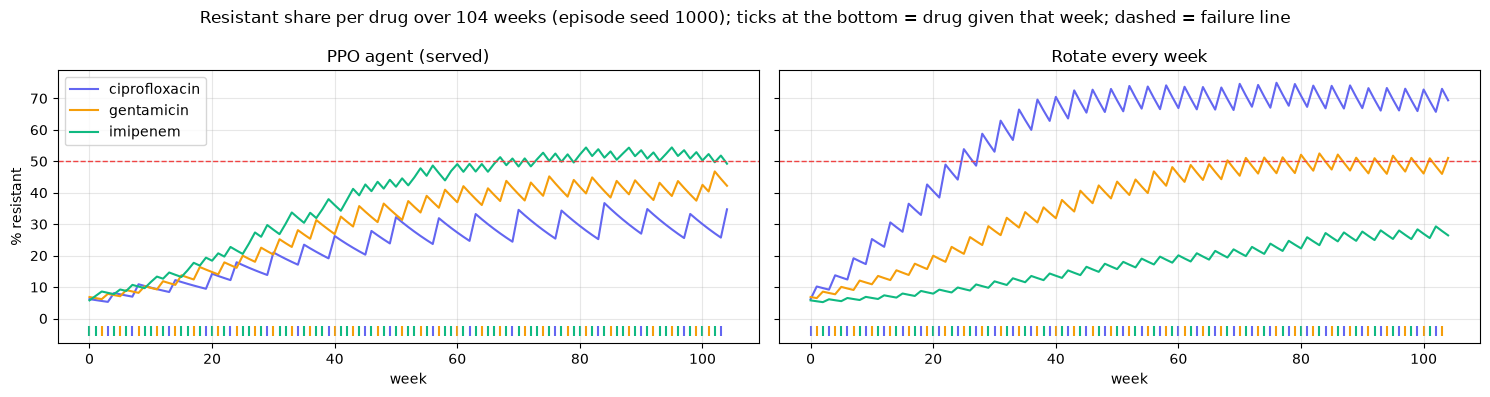

In [10]:
def trace(policy, seed=1000):
    e = rl_env.CyclingEnv(decay=0.05)
    obs, _ = e.reset(seed=seed)
    shares, given = [e.r.copy()], []
    for t in range(e.weeks):
        a = policy(obs, t)
        given.append(a)
        obs, *_ = e.step(a)
        shares.append(e.r.copy())
    return np.array(shares), np.array(given)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
colours = ['#6366f1', '#f59e0b', '#10b981']
for ax, (title, pol) in zip(axes, [('PPO agent (served)', agent.policy_for(rl_env.DRUGS)), ('Rotate every week', rl_env.cycle(1))]):
    shares, given = trace(pol)
    for i, d in enumerate(rl_env.DRUGS):
        ax.plot(100 * shares[:, i], color=colours[i], label=d)
    ax.scatter(np.arange(len(given)), [-4] * len(given), c=[colours[g] for g in given], marker='|', s=60)
    ax.axhline(50, color='#ef4444', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel('week'); ax.grid(alpha=0.3)
axes[0].set_ylabel('% resistant'); axes[0].legend(loc='upper left')
plt.suptitle('Resistant share per drug over 104 weeks (episode seed 1000); ticks at the bottom = drug given that week; dashed = failure line')
plt.tight_layout(); plt.show()

## 6. What the website shows

For a what-if simulation with ciprofloxacin, gentamicin or imipenem, `/api/timeline/` adds an `rl` block: the agent's plan and every fixed schedule on the same simulation, and the best of them. The same block comes from `amrpredict.plan_treatment()` in the library.

In [11]:
block = agent.block('ciprofloxacin', 12)
print('drugs:', block['drugs'], '| best:', block['best'])
pd.DataFrame([{'policy': p['label'], 'drug each week': ' '.join(d[:4] for d in p['policy']),
               'first failed week': p['failure_week'] if p['failure_week'] is not None else 'none in 12 weeks',
               'effective weeks (of 12)': p.get('effective_weeks')}
              for p in block['policies']])

drugs: ['ciprofloxacin', 'gentamicin', 'imipenem'] | best: rl


,policy,drug each week,first failed week,effective weeks (of 12)
0,RL agent,gent imip gent imip cipr gent imip imip gent c...,none in 12 weeks,12
1,Always ciprofloxacin,cipr cipr cipr cipr cipr cipr cipr cipr cipr c...,7,6
2,Always gentamicin,gent gent gent gent gent gent gent gent gent g...,12,11
3,Always imipenem,imip imip imip imip imip imip imip imip imip i...,none in 12 weeks,12
4,"Cycle Ciprofloxacin → gentamicin → imipenem, e...",cipr gent imip cipr gent imip cipr gent imip c...,none in 12 weeks,12
5,"Cycle Ciprofloxacin → gentamicin → imipenem, e...",cipr cipr cipr cipr gent gent gent gent imip i...,none in 12 weeks,12
6,Lowest resistance first (greedy),gent gent cipr imip gent imip cipr imip gent i...,none in 12 weeks,12
